# Ejercicio pandas estadística
Para este ejercicio se ha utilizado [un dataset de un concurso de kaggle](https://www.kaggle.com/nickhould/craft-cans), cuyo reto consiste en predecir el tipo de cerveza en función de sus características (nivel de alcohol, amargura, tamaño...).

# Ejercicio 1
Importa las librerias que consideres

In [115]:
import pandas as pd
import numpy as np

## Ejercicio 2
1. Importa el dataset "datasets_beer.csv"
2. Imprime por pantalla los primeros registros.
3. ¿Cuáles son sus columnas?
4. ¿Qué dimensiones tiene el DataFrame?

In [116]:
beers = pd.read_csv("./data/datasets_beers.csv")
beers.head()

,Unnamed: 0,abv,ibu,id,name,style,brewery_id,ounces
0,0,0.050,NaN,1436,Pub Beer,American Pale Lager,408,12.0
1,1,0.066,NaN,2265,Devil's Cup,American Pale Ale (APA),177,12.0
2,2,0.071,NaN,2264,Rise of the Phoenix,American IPA,177,12.0
3,3,0.090,NaN,2263,Sinister,American Double / Imperial IPA,177,12.0
4,4,0.075,NaN,2262,Sex and Candy,American IPA,177,12.0


In [117]:
beers.info()

<class 'pandas.DataFrame'>
RangeIndex: 2410 entries, 0 to 2409
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  2410 non-null   int64  
 1   abv         2348 non-null   float64
 2   ibu         1405 non-null   float64
 3   id          2410 non-null   int64  
 4   name        2410 non-null   str    
 5   style       2405 non-null   str    
 6   brewery_id  2410 non-null   int64  
 7   ounces      2410 non-null   float64
dtypes: float64(3), int64(3), str(2)
memory usage: 150.8 KB


In [118]:
beers.describe().round(2)

,Unnamed: 0,abv,ibu,id,brewery_id,ounces
count,2410.00,2348.00,1405.00,2410.00,2410.00,2410.00
mean,1204.50,0.06,42.71,1431.11,231.75,13.59
std,695.85,0.01,25.95,752.46,157.69,2.35
min,0.00,0.00,4.00,1.00,0.00,8.40
25%,602.25,0.05,21.00,808.25,93.00,12.00
50%,1204.50,0.06,35.00,1453.50,205.00,12.00
75%,1806.75,0.07,64.00,2075.75,366.00,16.00
max,2409.00,0.13,138.00,2692.00,557.00,32.00


In [119]:
beers.columns

Index(['Unnamed: 0', 'abv', 'ibu', 'id', 'name', 'style', 'brewery_id',
       'ounces'],
      dtype='str')

In [120]:
print(beers.ndim)
print(beers.shape)

2
(2410, 8)


## Ejercicio 3
[Elimina la columna "Unnamed: 0"](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.drop.html)

In [121]:
beers = beers.drop(columns=["Unnamed: 0"])
beers.head()

,abv,ibu,id,name,style,brewery_id,ounces
0,0.050,NaN,1436,Pub Beer,American Pale Lager,408,12.0
1,0.066,NaN,2265,Devil's Cup,American Pale Ale (APA),177,12.0
2,0.071,NaN,2264,Rise of the Phoenix,American IPA,177,12.0
3,0.090,NaN,2263,Sinister,American Double / Imperial IPA,177,12.0
4,0.075,NaN,2262,Sex and Candy,American IPA,177,12.0


In [122]:
# guardas csv sin índices para que no duplique luego índices
beers.to_csv("prueba_guardado_cervezas.csv", index=False)

In [123]:
beers = pd.read_csv("prueba_guardado_cervezas.csv")
beers

,abv,ibu,id,name,style,brewery_id,ounces
0,0.050,NaN,1436,Pub Beer,American Pale Lager,408,12.0
1,0.066,NaN,2265,Devil's Cup,American Pale Ale (APA),177,12.0
2,0.071,NaN,2264,Rise of the Phoenix,American IPA,177,12.0
3,0.090,NaN,2263,Sinister,American Double / Imperial IPA,177,12.0
4,0.075,NaN,2262,Sex and Candy,American IPA,177,12.0
...,...,...,...,...,...,...,...
2405,0.067,45.0,928,Belgorado,Belgian IPA,424,12.0
2406,0.052,NaN,807,Rail Yard Ale,American Amber / Red Ale,424,12.0
2407,0.055,NaN,620,B3K Black Lager,Schwarzbier,424,12.0
2408,0.055,40.0,145,Silverback Pale Ale,American Pale Ale (APA),424,12.0


## Ejercicio 4
¿Cuántas filas y columnas tiene el dataset?

In [124]:
beers.shape

(2410, 7)

## Ejercicio 5
¿De qué tipo son los datos?

In [125]:
beers.info()

<class 'pandas.DataFrame'>
RangeIndex: 2410 entries, 0 to 2409
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   abv         2348 non-null   float64
 1   ibu         1405 non-null   float64
 2   id          2410 non-null   int64  
 3   name        2410 non-null   str    
 4   style       2405 non-null   str    
 5   brewery_id  2410 non-null   int64  
 6   ounces      2410 non-null   float64
dtypes: float64(3), int64(2), str(2)
memory usage: 131.9 KB


In [126]:
beers.dtypes

abv           float64
ibu           float64
id              int64
name              str
style             str
brewery_id      int64
ounces        float64
dtype: object

## Ejercicio 6
Obtén en un nuevo DataFrame un resumen con las principales estadísticas de las columnas numéricas: mean, max, count, cuartiles...

In [127]:
beers[["abv", "ibu", "ounces"]].describe().round(2)

,abv,ibu,ounces
count,2348.00,1405.00,2410.00
mean,0.06,42.71,13.59
std,0.01,25.95,2.35
min,0.00,4.00,8.40
25%,0.05,21.00,12.00
50%,0.06,35.00,12.00
75%,0.07,64.00,16.00
max,0.13,138.00,32.00


In [128]:
beers.describe().round(2)

,abv,ibu,id,brewery_id,ounces
count,2348.00,1405.00,2410.00,2410.00,2410.00
mean,0.06,42.71,1431.11,231.75,13.59
std,0.01,25.95,752.46,157.69,2.35
min,0.00,4.00,1.00,0.00,8.40
25%,0.05,21.00,808.25,93.00,12.00
50%,0.06,35.00,1453.50,205.00,12.00
75%,0.07,64.00,2075.75,366.00,16.00
max,0.13,138.00,2692.00,557.00,32.00


In [129]:
# beers[["abv", "ibu", "ounces"]].aggregate("abv": ['mean', 'count'],
#                                           "ibu": ["max"])

## Ejercicio 7
¿Cuántas birras hay de cada estilo en este dataset? [Investiga en la documentación de Series](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.Series.html) si puedes hacer un conteo de valores.

In [130]:
beers.head()

,abv,ibu,id,name,style,brewery_id,ounces
0,0.050,NaN,1436,Pub Beer,American Pale Lager,408,12.0
1,0.066,NaN,2265,Devil's Cup,American Pale Ale (APA),177,12.0
2,0.071,NaN,2264,Rise of the Phoenix,American IPA,177,12.0
3,0.090,NaN,2263,Sinister,American Double / Imperial IPA,177,12.0
4,0.075,NaN,2262,Sex and Candy,American IPA,177,12.0


In [131]:
pd.Series(beers["style"].value_counts())

style
American IPA                      424
American Pale Ale (APA)           245
American Amber / Red Ale          133
American Blonde Ale               108
American Double / Imperial IPA    105
                                 ... 
American Malt Liquor                1
Grisette                            1
Flanders Oud Bruin                  1
Braggot                             1
Low Alcohol Beer                    1
Name: count, Length: 99, dtype: int64

In [132]:
beers.groupby("style")[["name"]].count().sort_values(by="name", ascending=False)

,name
style,
American IPA,424
American Pale Ale (APA),245
American Amber / Red Ale,133
American Blonde Ale,108
American Double / Imperial IPA,105
...,...
Kristalweizen,1
Other,1
Low Alcohol Beer,1


In [133]:
# agrupa los Nan como un estilo único, por eso salen 100 con unique()
len(beers["style"].unique())

100

In [134]:
beers["style"] = beers["style"].fillna("Missing style")

In [135]:
beers[beers["style"] == "Missing style"]["style"].value_counts()

style
Missing style    5
Name: count, dtype: int64

## Ejercicio 8
1. Imprime por pantalla los registros desde el décimo hasta el vigésimo
2. De esos registros, imprime por pantalla desde la columna `name` a `ounces`, ambas incluidas
3. Quédate con las columnas `abv`, `ibu` y `ounces`, y además quédate sólo con los registros 10 al 20.
4. Convierte el resultado del apartado 3 en un array de `numpy`

In [136]:
# 1
beers.loc[9:19]

,abv,ibu,id,name,style,brewery_id,ounces
9,0.086,NaN,2131,Cone Crusher,American Double / Imperial IPA,177,12.0
10,0.072,NaN,2099,Sophomoric Saison,Saison / Farmhouse Ale,177,12.0
11,0.073,NaN,2098,Regional Ring Of Fire,Saison / Farmhouse Ale,177,12.0
12,0.069,NaN,2097,Garce Selé,Saison / Farmhouse Ale,177,12.0
13,0.085,NaN,1980,Troll Destroyer,Belgian IPA,177,12.0
14,0.061,60.0,1979,Bitter Bitch,American Pale Ale (APA),177,12.0
15,0.060,NaN,2318,Ginja Ninja,Cider,154,12.0
16,0.060,NaN,2170,Cherried Away,Cider,154,12.0
17,0.060,NaN,2169,Rhubarbarian,Cider,154,12.0
18,0.060,NaN,1502,BrightCider,Cider,154,12.0


In [137]:
beers.loc[9:19, "name":"ounces"]

,name,style,brewery_id,ounces
9,Cone Crusher,American Double / Imperial IPA,177,12.0
10,Sophomoric Saison,Saison / Farmhouse Ale,177,12.0
11,Regional Ring Of Fire,Saison / Farmhouse Ale,177,12.0
12,Garce Selé,Saison / Farmhouse Ale,177,12.0
13,Troll Destroyer,Belgian IPA,177,12.0
14,Bitter Bitch,American Pale Ale (APA),177,12.0
15,Ginja Ninja,Cider,154,12.0
16,Cherried Away,Cider,154,12.0
17,Rhubarbarian,Cider,154,12.0
18,BrightCider,Cider,154,12.0


In [138]:
beers.iloc[10:21, beers.columns.get_loc("name"):beers.columns.get_loc("ounces")]

,name,style,brewery_id
10,Sophomoric Saison,Saison / Farmhouse Ale,177
11,Regional Ring Of Fire,Saison / Farmhouse Ale,177
12,Garce Selé,Saison / Farmhouse Ale,177
13,Troll Destroyer,Belgian IPA,177
14,Bitter Bitch,American Pale Ale (APA),177
15,Ginja Ninja,Cider,154
16,Cherried Away,Cider,154
17,Rhubarbarian,Cider,154
18,BrightCider,Cider,154
19,He Said Baltic-Style Porter,Baltic Porter,368


In [139]:
beers.loc[10:20, ["abv","ibu", "ounces"]]

,abv,ibu,ounces
10,0.072,NaN,12.0
11,0.073,NaN,12.0
12,0.069,NaN,12.0
13,0.085,NaN,12.0
14,0.061,60.0,12.0
15,0.060,NaN,12.0
16,0.060,NaN,12.0
17,0.060,NaN,12.0
18,0.060,NaN,12.0
19,0.082,NaN,12.0


In [140]:
# 4
np.array(beers.loc[9:19, ["abv","ibu", "ounces"]])

array([[ 0.086,    nan, 12.   ],
       [ 0.072,    nan, 12.   ],
       [ 0.073,    nan, 12.   ],
       [ 0.069,    nan, 12.   ],
       [ 0.085,    nan, 12.   ],
       [ 0.061, 60.   , 12.   ],
       [ 0.06 ,    nan, 12.   ],
       [ 0.06 ,    nan, 12.   ],
       [ 0.06 ,    nan, 12.   ],
       [ 0.06 ,    nan, 12.   ],
       [ 0.082,    nan, 12.   ]])

## Ejercicio 9
¿Cuántas onzas pesan todas las birras del dataset?

In [141]:
beers.head()

,abv,ibu,id,name,style,brewery_id,ounces
0,0.050,NaN,1436,Pub Beer,American Pale Lager,408,12.0
1,0.066,NaN,2265,Devil's Cup,American Pale Ale (APA),177,12.0
2,0.071,NaN,2264,Rise of the Phoenix,American IPA,177,12.0
3,0.090,NaN,2263,Sinister,American Double / Imperial IPA,177,12.0
4,0.075,NaN,2262,Sex and Candy,American IPA,177,12.0


In [142]:
beers["ounces"].sum()

np.float64(32757.3)

## Ejercicio 10
El amargor de las cervezas se mide por su nivel de IBUs.
1. ¿Cuál es el amargor medio de las cervezas?
2. ¿El máximo? ¿Y el mínimo?
3. ¿Qué cerveza es la que tiene el amargor máximo? ¿Cuál es la de amargor mínimo?

In [143]:
beers.info()

<class 'pandas.DataFrame'>
RangeIndex: 2410 entries, 0 to 2409
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   abv         2348 non-null   float64
 1   ibu         1405 non-null   float64
 2   id          2410 non-null   int64  
 3   name        2410 non-null   str    
 4   style       2410 non-null   str    
 5   brewery_id  2410 non-null   int64  
 6   ounces      2410 non-null   float64
dtypes: float64(3), int64(2), str(2)
memory usage: 131.9 KB


In [144]:
# 1
beers["ibu"].mean()

np.float64(42.71316725978647)

In [145]:
# 2
ibu_max = beers["ibu"].max()
ibu_max

np.float64(138.0)

In [146]:
ibu_min = beers["ibu"].min()
ibu_min

np.float64(4.0)

In [147]:
# 3

beers.loc[beers["ibu"] == ibu_min]

,abv,ibu,id,name,style,brewery_id,ounces
106,0.056,4.0,1350,Summer Solstice,Cream Ale,171,12.0
112,0.056,4.0,753,Summer Solstice Cerveza Crema (2009),Cream Ale,171,12.0
117,0.056,4.0,77,Summer Solstice (2011),Cream Ale,171,12.0


In [148]:
beers.loc[beers["ibu"] == ibu_max]

,abv,ibu,id,name,style,brewery_id,ounces
147,0.082,138.0,980,Bitter Bitch Imperial IPA,American Double / Imperial IPA,374,12.0


## Ejercicio 11
No queda muy claro cuánto de dispar, de dispersa, es la medida de IBU. Mediante estadística descriptiva (una o dos métricas, sin gráficas), razona la dispersión de la variable IBU.

In [149]:
beers["ibu"].describe()

count    1405.000000
mean       42.713167
std        25.954066
min         4.000000
25%        21.000000
50%        35.000000
75%        64.000000
max       138.000000
Name: ibu, dtype: float64

In [150]:
# Mirando máx y min, media y cuartiles: los datos están concentrados en valores pequeños: asimetría positiva

<Axes: >

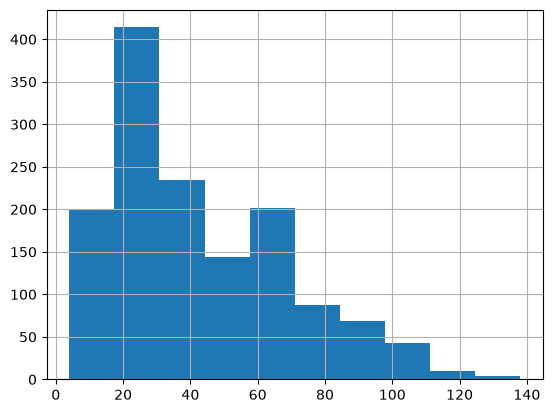

In [151]:
beers["ibu"].hist()

In [ ]:
# Si queremos sustituir los NaN de amargor:
# Supongamos que las cervezas que no tienen amargor van a tener un amargor aproximado a la media 
# (para que no la alteren demasiado). le estamos asignado el valor de la mediana de toodo el conjunto

beers["ibu"] = beers["ibu"].fillna(beers["ibu"].median())

In [110]:
beers.info()

<class 'pandas.DataFrame'>
RangeIndex: 2410 entries, 0 to 2409
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   abv         2348 non-null   float64
 1   ibu         2410 non-null   float64
 2   id          2410 non-null   int64  
 3   name        2410 non-null   str    
 4   style       2410 non-null   str    
 5   brewery_id  2410 non-null   int64  
 6   ounces      2410 non-null   float64
dtypes: float64(3), int64(2), str(2)
memory usage: 131.9 KB


<Axes: >

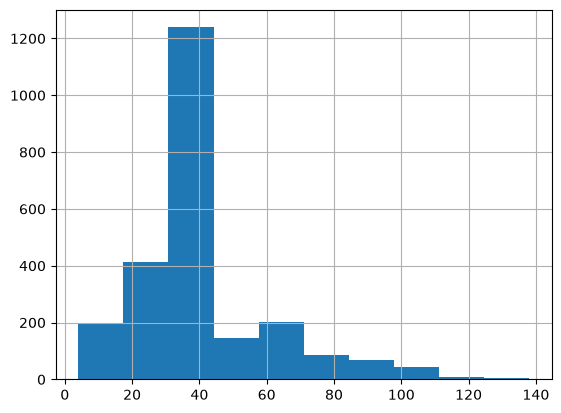

In [ ]:
beers["ibu"].hist()
# ha cambiado mucho pues hemos metido muchos valores de la mediana

In [153]:
# Otra manera, mejor, es asignarle la mediana según el estilo de las cervezas que tienen amargor NaN
median_ibu_style = beers.groupby("style")[["ibu"]].median()
median_ibu_style

,ibu
style,
Abbey Single Ale,22.0
Altbier,36.5
American Adjunct Lager,9.0
American Amber / Red Ale,31.0
American Amber / Red Lager,23.0
...,...
Tripel,27.5
Vienna Lager,23.5
Wheat Ale,24.0


In [ ]:
# Luego los que queden, se rellenan con la mediana de todos los valores 
# (mirar lo del profe para ver los siguientes pasos)

## Ejercicio 12
¿Existe alguna relación lineal entre las variables numéricas del dataset? Intenta pintar este razonamiento mediante un gráfico

In [154]:
beers.head()

,abv,ibu,id,name,style,brewery_id,ounces
0,0.050,NaN,1436,Pub Beer,American Pale Lager,408,12.0
1,0.066,NaN,2265,Devil's Cup,American Pale Ale (APA),177,12.0
2,0.071,NaN,2264,Rise of the Phoenix,American IPA,177,12.0
3,0.090,NaN,2263,Sinister,American Double / Imperial IPA,177,12.0
4,0.075,NaN,2262,Sex and Candy,American IPA,177,12.0


In [157]:
beers[["abv", "ibu", "ounces"]].corr()

,abv,ibu,ounces
abv,1.000000,0.670621,0.172529
ibu,0.670621,1.000000,0.054691
ounces,0.172529,0.054691,1.000000


In [160]:
import seaborn as sns

<Axes: >

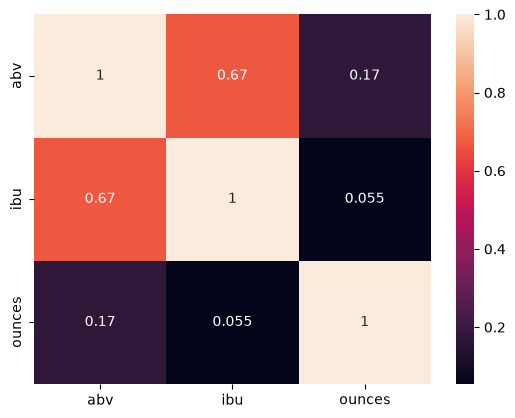

In [161]:
sns.heatmap(beers[["abv", "ibu", "ounces"]].corr(), annot=True)

Según los índices de Pearson y el consecuente mapa de calor, no hay relación lineal entre las variables numéricas. 

## Ejercicio 13
Representa el nivel de alcohol (columna `abv`) en un histograma. ¿Se trata de una distribución simétrica o asimétrica?

<Axes: >

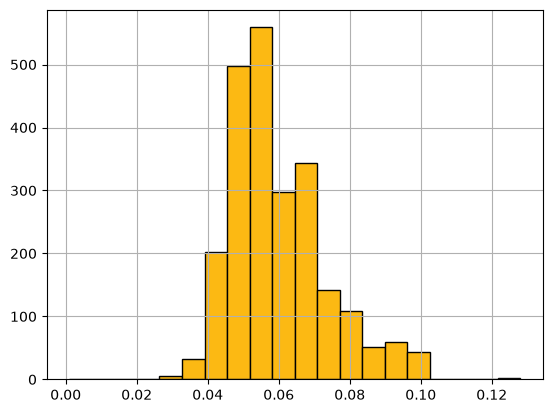

In [100]:
beers["abv"].hist(bins=20, color= "#fcb913", edgecolor="black")

Asimetrica positiva

In [ ]:
beers["abv"].skew()

# positivo cercano a 1 --> asimétrica postica

np.float64(0.9584771340361382)

## Ejercicio 14
Representa mediante un *boxplot* de `seaborn` la variable `abv`

<Axes: ylabel='abv'>

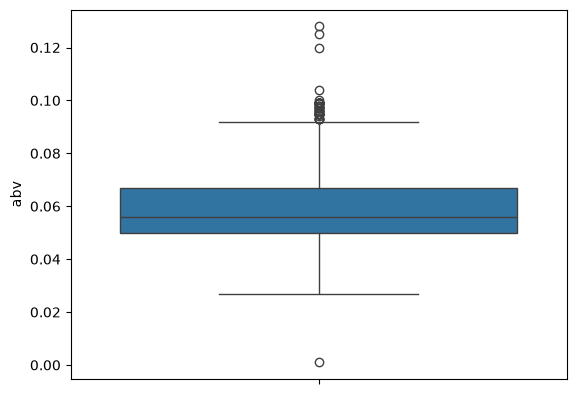

In [101]:
sns.boxplot(beers["abv"])

## Ejercicio 15
1. ¿Qué estilos son los que tienen en media más alcohol?
2. ¿Y los estilos que son en media más amargos?

In [102]:
beers.groupby("style")[["abv"]].mean().sort_values(by="abv", ascending=False)

,abv
style,
English Barleywine,0.107667
Quadrupel (Quad),0.104000
American Barleywine,0.099000
American Malt Liquor,0.099000
Russian Imperial Stout,0.097636
...,...
Berliner Weissbier,0.043909
English Dark Mild Ale,0.041500
Light Lager,0.040417


In [103]:
beers.groupby("style")[["ibu"]].mean().sort_values(by="ibu", ascending=False)

,ibu
style,
American Barleywine,96.00
American Double / Imperial IPA,93.32
Russian Imperial Stout,86.50
American Double / Imperial Pilsner,85.00
Belgian Strong Dark Ale,72.00
...,...
Kristalweizen,NaN
Low Alcohol Beer,NaN
Mead,NaN


## Ejercicio 16
Carga el datasets de cervecerias `datasets_breweries.csv`

In [165]:
breweries = pd.read_csv("./data/datasets_breweries.csv")
breweries

,Unnamed: 0,name,city,state
0,0,NorthGate Brewing,Minneapolis,MN
1,1,Against the Grain Brewery,Louisville,KY
2,2,Jack's Abby Craft Lagers,Framingham,MA
3,3,Mike Hess Brewing Company,San Diego,CA
4,4,Fort Point Beer Company,San Francisco,CA
...,...,...,...,...
553,553,Covington Brewhouse,Covington,LA
554,554,Dave's Brewfarm,Wilson,WI
555,555,Ukiah Brewing Company,Ukiah,CA
556,556,Butternuts Beer and Ale,Garrattsville,NY


In [166]:
breweries.info()

<class 'pandas.DataFrame'>
RangeIndex: 558 entries, 0 to 557
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Unnamed: 0  558 non-null    int64
 1   name        558 non-null    str  
 2   city        558 non-null    str  
 3   state       558 non-null    str  
dtypes: int64(1), str(3)
memory usage: 17.6 KB


## Ejercicio 17
1. Renombra la columna `Unnamed: 0` como `brewery_id`
2. Renombra también la columna `name` por `brewery_name`. ¿Puedes hacer ambos apartados en una sola sentencia?

In [168]:
breweries= breweries.rename(columns={"Unnamed: 0": "brewery_id", "name": "brewery_name"})
breweries

,brewery_id,brewery_name,city,state
0,0,NorthGate Brewing,Minneapolis,MN
1,1,Against the Grain Brewery,Louisville,KY
2,2,Jack's Abby Craft Lagers,Framingham,MA
3,3,Mike Hess Brewing Company,San Diego,CA
4,4,Fort Point Beer Company,San Francisco,CA
...,...,...,...,...
553,553,Covington Brewhouse,Covington,LA
554,554,Dave's Brewfarm,Wilson,WI
555,555,Ukiah Brewing Company,Ukiah,CA
556,556,Butternuts Beer and Ale,Garrattsville,NY


## Ejercicio 18
Junta los dos datasets que tienes

In [106]:
beers.info()

<class 'pandas.DataFrame'>
RangeIndex: 2410 entries, 0 to 2409
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   abv         2348 non-null   float64
 1   ibu         1405 non-null   float64
 2   id          2410 non-null   int64  
 3   name        2410 non-null   str    
 4   style       2405 non-null   str    
 5   brewery_id  2410 non-null   int64  
 6   ounces      2410 non-null   float64
dtypes: float64(3), int64(2), str(2)
memory usage: 131.9 KB


In [107]:
beers.describe()

,abv,ibu,id,brewery_id,ounces
count,2348.000000,1405.000000,2410.000000,2410.000000,2410.000000
mean,0.059773,42.713167,1431.113278,231.749793,13.592241
std,0.013542,25.954066,752.459975,157.685604,2.352204
min,0.001000,4.000000,1.000000,0.000000,8.400000
25%,0.050000,21.000000,808.250000,93.000000,12.000000
50%,0.056000,35.000000,1453.500000,205.000000,12.000000
75%,0.067000,64.000000,2075.750000,366.000000,16.000000
max,0.128000,138.000000,2692.000000,557.000000,32.000000


In [108]:
breweries.info()

<class 'pandas.DataFrame'>
RangeIndex: 558 entries, 0 to 557
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   brewery_id    558 non-null    int64
 1   brewery_name  558 non-null    str  
 2   city          558 non-null    str  
 3   state         558 non-null    str  
dtypes: int64(1), str(3)
memory usage: 17.6 KB


In [109]:
breweries.describe()

,brewery_id
count,558.000000
mean,278.500000
std,161.224998
min,0.000000
25%,139.250000
50%,278.500000
75%,417.750000
max,557.000000


In [169]:
# Primero, haces un outer para ver ver qué se te queda fuera, 
# teniendo en mente que el dataset al que le quiero añadir info es al de las cerves (beers)
completo = pd.merge(beers, breweries, on="brewery_id", how="outer", indicator=True)
completo.head()

,abv,ibu,id,name,style,brewery_id,ounces,brewery_name,city,state,_merge
0,0.045,50.0,2692,Get Together,American IPA,0,16.0,NorthGate Brewing,Minneapolis,MN,both
1,0.049,26.0,2691,Maggie's Leap,Milk / Sweet Stout,0,16.0,NorthGate Brewing,Minneapolis,MN,both
2,0.048,19.0,2690,Wall's End,English Brown Ale,0,16.0,NorthGate Brewing,Minneapolis,MN,both
3,0.060,38.0,2689,Pumpion,Pumpkin Ale,0,16.0,NorthGate Brewing,Minneapolis,MN,both
4,0.060,25.0,2688,Stronghold,American Porter,0,16.0,NorthGate Brewing,Minneapolis,MN,both


In [170]:
completo[completo["_merge"] != "both"]

,abv,ibu,id,name,style,brewery_id,ounces,brewery_name,city,state,_merge


In [171]:
completo = pd.merge(beers, breweries, on="brewery_id", how="left")
completo.head()

,abv,ibu,id,name,style,brewery_id,ounces,brewery_name,city,state
0,0.050,NaN,1436,Pub Beer,American Pale Lager,408,12.0,10 Barrel Brewing Company,Bend,OR
1,0.066,NaN,2265,Devil's Cup,American Pale Ale (APA),177,12.0,18th Street Brewery,Gary,IN
2,0.071,NaN,2264,Rise of the Phoenix,American IPA,177,12.0,18th Street Brewery,Gary,IN
3,0.090,NaN,2263,Sinister,American Double / Imperial IPA,177,12.0,18th Street Brewery,Gary,IN
4,0.075,NaN,2262,Sex and Candy,American IPA,177,12.0,18th Street Brewery,Gary,IN


In [172]:
completo.info()

<class 'pandas.DataFrame'>
RangeIndex: 2410 entries, 0 to 2409
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   abv           2348 non-null   float64
 1   ibu           1405 non-null   float64
 2   id            2410 non-null   int64  
 3   name          2410 non-null   str    
 4   style         2410 non-null   str    
 5   brewery_id    2410 non-null   int64  
 6   ounces        2410 non-null   float64
 7   brewery_name  2410 non-null   str    
 8   city          2410 non-null   str    
 9   state         2410 non-null   str    
dtypes: float64(3), int64(2), str(5)
memory usage: 188.4 KB


## Ejercicio 19
1. ¿Cuántos estados diferentes hay?
2. ¿Y ciudades diferentes?
3. ¿Cuántas cervecerías hay?

In [112]:
# 1
completo["state"].nunique()

51

In [113]:
# 2
completo["city"].nunique()

384

In [114]:
# 3
completo["brewery_id"].nunique()

558

In [115]:
# Agrupamos por nombre y contamos cuántas IDs únicas tiene cada uno
duplicados = completo.groupby('brewery_name')['brewery_id'].nunique()

# Filtramos para ver solo los que tienen más de 1 ID y los ordenamos
print(duplicados[duplicados > 1].sort_values(ascending=False))

brewery_name
Blackrocks Brewery         2
Blue Mountain Brewery      2
Lucette Brewing Company    2
Oskar Blues Brewery        2
Otter Creek Brewing        2
Sly Fox Brewing Company    2
Summit Brewing Company     2
Name: brewery_id, dtype: int64


## Ejercicio 20
Agrupa por estado y ciudad, la media, mediana y máximo nivel de alcohol

In [116]:
completo.groupby(["state", "city"])[["abv"]].aggregate(["mean", "median", "max"])

abv               
                      mean  median    max
state city                               
AK    Anchorage   0.054200  0.0520  0.063
      Juneau      0.053000  0.0530  0.053
      Soldotna    0.058500  0.0580  0.068
      Talkeetna   0.059500  0.0585  0.065
AL    Birmingham  0.065400  0.0600  0.093
...                    ...     ...    ...
WI    Wilson      0.055000  0.0550  0.055
WV    Lewisburg   0.062000  0.0620  0.067
WY    Jackson     0.054857  0.0520  0.068
      Pinedale    0.061000  0.0610  0.072
      Sheridan    0.052833  0.0480  0.070

[401 rows x 3 columns]

## Ejercicio 21
¿Cuáles son las cervezas más amargas que se consumen en Indiana, estado = `IN`?

In [117]:
completo["state"] = completo["state"].str.strip()

In [118]:
completo.head()

,abv,ibu,id,name,style,brewery_id,ounces,brewery_name,city,state
0,0.050,NaN,1436,Pub Beer,American Pale Lager,408,12.0,10 Barrel Brewing Company,Bend,OR
1,0.066,NaN,2265,Devil's Cup,American Pale Ale (APA),177,12.0,18th Street Brewery,Gary,IN
2,0.071,NaN,2264,Rise of the Phoenix,American IPA,177,12.0,18th Street Brewery,Gary,IN
3,0.090,NaN,2263,Sinister,American Double / Imperial IPA,177,12.0,18th Street Brewery,Gary,IN
4,0.075,NaN,2262,Sex and Candy,American IPA,177,12.0,18th Street Brewery,Gary,IN


In [127]:
completo[completo["state"] == "IN"][["ibu", "name"]].sort_values(by="ibu", ascending=False)

,ibu,name
479,115.0,Hopkick Dropkick
2191,115.0,Overlord Imperial IPA
811,104.0,Half Cycle IPA
2062,91.0,Isis
2189,90.0,Csar
...,...,...
2056,NaN,The Deuce
2061,NaN,Chaka
2190,NaN,Klingon Warnog Roggen Dunkel
2277,NaN,Dragonfly IPA


## Ejercicio 22
Obtén una tabla con los principales estadísticos del campo `ibu`,  a nivel ciudad

In [129]:
completo.groupby("city")["ibu"].describe().round()

,count,mean,std,min,25%,50%,75%,max
city,,,,,,,,
Abingdon,1.0,135.0,NaN,135.0,135.0,135.0,135.0,135.0
Abita Springs,3.0,27.0,21.0,13.0,15.0,17.0,34.0,52.0
Ada,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Afton,4.0,43.0,20.0,22.0,28.0,45.0,60.0,60.0
Airway Heights,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...
Woodinville,4.0,47.0,19.0,27.0,40.0,44.0,51.0,72.0
Worcester,1.0,69.0,NaN,69.0,69.0,69.0,69.0,69.0
Yakima,2.0,54.0,23.0,38.0,46.0,54.0,62.0,70.0


## Ejercicio 23
Consigue en un DataFrame de todas las cervezas en cuyas cervecerías al menos haya una cerveza con un `abv` mínimo 0.07.

In [140]:
alcohol_cerves_ids = completo[completo["abv"] >= 0.07]["brewery_id"].unique()
extraccion_abv = completo[completo["brewery_id"].isin(alcohol_cerves_ids)]
extraccion_abv

,abv,ibu,id,name,style,brewery_id,ounces,brewery_name,city,state
1,0.066,NaN,2265,Devil's Cup,American Pale Ale (APA),177,12.0,18th Street Brewery,Gary,IN
2,0.071,NaN,2264,Rise of the Phoenix,American IPA,177,12.0,18th Street Brewery,Gary,IN
3,0.090,NaN,2263,Sinister,American Double / Imperial IPA,177,12.0,18th Street Brewery,Gary,IN
4,0.075,NaN,2262,Sex and Candy,American IPA,177,12.0,18th Street Brewery,Gary,IN
5,0.077,NaN,2261,Black Exodus,Oatmeal Stout,177,12.0,18th Street Brewery,Gary,IN
...,...,...,...,...,...,...,...,...,...,...
2405,0.067,45.0,928,Belgorado,Belgian IPA,424,12.0,Wynkoop Brewing Company,Denver,CO
2406,0.052,NaN,807,Rail Yard Ale,American Amber / Red Ale,424,12.0,Wynkoop Brewing Company,Denver,CO
2407,0.055,NaN,620,B3K Black Lager,Schwarzbier,424,12.0,Wynkoop Brewing Company,Denver,CO
2408,0.055,40.0,145,Silverback Pale Ale,American Pale Ale (APA),424,12.0,Wynkoop Brewing Company,Denver,CO


In [144]:
extraccion_abv.info()

<class 'pandas.DataFrame'>
Index: 1483 entries, 1 to 2409
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   abv           1460 non-null   float64
 1   ibu           895 non-null    float64
 2   id            1483 non-null   int64  
 3   name          1483 non-null   str    
 4   style         1480 non-null   str    
 5   brewery_id    1483 non-null   int64  
 6   ounces        1483 non-null   float64
 7   brewery_name  1483 non-null   str    
 8   city          1483 non-null   str    
 9   state         1483 non-null   str    
dtypes: float64(3), int64(2), str(5)
memory usage: 127.4 KB


## Ejercicio 24
Teniendo en cuenta la media de amargor de todas las cervezas, obtén una tabla con las cervezas cuyos estados tengan una media de amargor en cerveza por encima de la media

In [161]:
ibu_mean= completo["ibu"].mean()

ibu_states_mean = completo.groupby("state")[["ibu"]].mean()

In [165]:
ibu_states_alta_mean = ibu_states_mean[ibu_states_mean["ibu"] > ibu_mean]
ibu_states_alta_mean.head()

,ibu
state,
AL,51.222222
CA,46.281481
CO,47.431507
DC,55.250000
DE,52.000000


In [172]:
ibu_states_alta_mean_df = pd.merge(ibu_states_alta_mean, completo, on="state", how="left", suffixes=["_mean", "_original"]).sort_values(by="ibu_mean", ascending=False)
ibu_states_alta_mean_df.head()

,state,ibu_mean,abv,ibu_original,id,name,style,brewery_id,ounces,brewery_name,city
1287,WV,57.5,0.067,71.0,2313,Mothman Black IPA,American Black Ale,156,12.0,Greenbrier Valley Brewing Company,Lewisburg
1286,WV,57.5,0.057,44.0,2314,Wild Trail Pale Ale,American Pale Ale (APA),156,12.0,Greenbrier Valley Brewing Company,Lewisburg
887,NM,57.0,0.080,NaN,305,Imperial Java Stout,Russian Imperial Stout,392,12.0,Santa Fe Brewing Company,Santa Fe
889,NM,57.0,0.066,NaN,217,Happy Camper IPA,American IPA,392,12.0,Santa Fe Brewing Company,Santa Fe
888,NM,57.0,0.055,NaN,304,Freestyle Pilsner,German Pilsener,392,12.0,Santa Fe Brewing Company,Santa Fe


In [ ]:
# Otra forma de hacerlo
estados_que_cumplen = ibu_states_mean[ibu_states_mean > ibu_mean].index
completo[completo["state"].isin(estados_que_cumplen)].sort_values(by="ibu", ascending=False)

,abv,ibu,id,name,style,brewery_id,ounces,brewery_name,city,state
147,0.082,138.0,980,Bitter Bitch Imperial IPA,American Double / Imperial IPA,374,12.0,Astoria Brewing Company,Astoria,OR
2390,0.059,135.0,1676,Troopers Alley IPA,American IPA,344,12.0,Wolf Hills Brewing Company,Abingdon,VA
525,0.090,130.0,2067,Dead-Eye DIPA,American Double / Imperial IPA,230,16.0,Cape Ann Brewing Company,Gloucester,MA
594,0.089,126.0,2440,Bay of Bengal Double IPA (2014),American Double / Imperial IPA,99,12.0,Christian Moerlein Brewing Company,Cincinnati,OH
2145,0.080,120.0,379,Heady Topper,American Double / Imperial IPA,272,16.0,The Alchemist,Waterbury,VT
...,...,...,...,...,...,...,...,...,...,...
2403,0.055,NaN,1045,Wynkoop Pumpkin Ale,Pumpkin Ale,424,12.0,Wynkoop Brewing Company,Denver,CO
2404,0.075,NaN,1035,Rocky Mountain Oyster Stout,American Stout,424,12.0,Wynkoop Brewing Company,Denver,CO
2406,0.052,NaN,807,Rail Yard Ale,American Amber / Red Ale,424,12.0,Wynkoop Brewing Company,Denver,CO
2407,0.055,NaN,620,B3K Black Lager,Schwarzbier,424,12.0,Wynkoop Brewing Company,Denver,CO
